## Étape 1 — Préparer Python et importer le fichier


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


chemin = "data/raw/dataset_tp_cleaning.csv"
try:
    df_brut = pd.read_csv(
        chemin, dtype="string",
        na_values=["?", "unknown", "Unknown", "not available", "not_a_date", "bad", "excellent"]
    )
    RACINE = ""
except FileNotFoundError:
    RACINE = "../"
    df_brut = pd.read_csv(
        RACINE + chemin, dtype="string",
        na_values=["?", "unknown", "Unknown", "not available", "not_a_date", "bad", "excellent"]
    )

print("Dimensions de départ :", df_brut.shape)
print(df_brut[["age", "plan", "device", "churned"]].head(3).to_string(index=False))

Dimensions de départ : (10000, 19)
age     plan     device churned
 58 STANDARD    Desktop      No
 44 Standard     Mobile     Yes
 36    Basic Smartphone     Yes


## Étape 2 — Faire le diagnostic initial


In [27]:
n_doublons = int(df_brut.duplicated().sum())
print("Doublons stricts :", n_doublons)

manquants = df_brut.isna().sum().sort_values(ascending=False)
print("\nValeurs manquantes par colonne :")
print(manquants.to_string())

print("\nFormules avant nettoyage :")
print(df_brut["plan"].value_counts(dropna=False).head(18).to_string())



Doublons stricts : 250

Valeurs manquantes par colonne :
annual_income_eur      342
age                    266
satisfaction_score     264
monthly_spend_eur      219
last_login             192
city                   178
payment_method         120
email                  117
customer_id             35
tenure_months           11
signup_date             11
plan                    11
full_name                0
gender                   0
country                  0
device                   0
support_tickets_12m      0
marketing_opt_in         0
churned                  0

Formules avant nettoyage :
plan
Basic         3960
Standard      3607
Premium       1845
Starter         58
Std             55
STANDARD        54
 BASIC          52
Basic Plan      51
basic           50
 Standard       47
standard        46
 Premium        37
PREMIUM         36
Pro             35
premium         26
Gold            17
VIP             13
<NA>            11


In [28]:
base = df_brut.drop_duplicates().copy()
df = base.copy()
print("Lignes au départ :", len(df_brut))
print("Lignes après suppression des copies :", len(df))
print("Lignes retirées :", len(df_brut) - len(df))

Lignes au départ : 10000
Lignes après suppression des copies : 9750
Lignes retirées : 250


## 4. Uniformiser les catégories


In [29]:
def nettoyer_categorie(serie, correspondances=None):
    texte = serie.str.strip().str.lower()
    if correspondances is not None:
        texte = texte.replace(correspondances)
    return texte.str.title()

df["plan"] = nettoyer_categorie(df["plan"], {
    "std": "standard", "basic plan": "basic"
})

df["device"] = nettoyer_categorie(df["device"], {
    "phone": "mobile", "smartphone": "mobile",
    "pc": "desktop", "computer": "desktop", "tab": "tablet"
})

df["payment_method"] = nettoyer_categorie(df["payment_method"], {
    "cb": "card", "credit card": "card", "pay pal": "paypal",
    "banktransfer": "bank transfer", "directdebit": "direct debit"
})

df["gender"] = nettoyer_categorie(df["gender"], {
    "m": "male", "man": "male", "homme": "male",
    "f": "female", "woman": "female", "femme": "female",
    "nb": "non-binary", "nonbinary": "non-binary", "non binary": "non-binary"
})
df["country"] = nettoyer_categorie(df["country"], {
    "fr": "france", "belgique": "belgium", "be": "belgium",
    "espagne": "spain", "es": "spain", "allemagne": "germany",
    "de": "germany", "italie": "italy", "it": "italy"
})
df["city"] = nettoyer_categorie(df["city"], {
    "tlse": "toulouse", "touluse": "toulouse", "pariis": "paris",
    "lionn": "lyon", "bordeau": "bordeaux", "montpelier": "montpellier",
    "marsseille": "marseille", "nante": "nantes", "lile": "lille",
    "renne": "rennes", "nce": "nice", "strasburg": "strasbourg",
    "grenoblle": "grenoble"
})

reponses = {"yes": 1, "y": 1, "true": 1, "1": 1,
            "no": 0, "n": 0, "false": 0, "0": 0}
for colonne in ["churned", "marketing_opt_in"]:
    df[colonne] = df[colonne].str.strip().str.lower().map(reponses).astype("Int64")

print("Formules après harmonisation :")
print(df["plan"].value_counts(dropna=False).to_string())
print("Churn inconnu après harmonisation :", df["churned"].isna().sum())

Formules après harmonisation :
plan
Basic       4020
Standard    3713
Premium     1891
Starter       54
Pro           33
Gold          16
Vip           13
<NA>          10
Churn inconnu après harmonisation : 0


## 5. Convertir les nombres sans inventer de valeurs


In [30]:
def convertir_nombre(serie, colonne):
    texte = serie.str.strip().str.lower()

    if colonne == "age":
        texte = texte.str.replace("years", "", regex=False).replace({"twenty nine": "29"})
    if colonne == "tenure_months":
        texte = texte.str.replace("months", "", regex=False)
    if colonne == "support_tickets_12m":
        texte = texte.str.replace("tickets", "", regex=False)
    if colonne == "satisfaction_score":
        texte = texte.str.replace("/10", "", regex=False)

    if colonne in ["annual_income_eur", "monthly_spend_eur"]:
        texte = texte.str.replace("eur", "", regex=False).str.replace("€", "", regex=False)
        if colonne == "annual_income_eur":
    
            texte = texte.str.replace(",", "", regex=False)
        else:

            texte = texte.str.replace(",", ".", regex=False)


    if colonne == "annual_income_eur":
        en_milliers = texte.str.strip().str.endswith("k").fillna(False)
        texte = texte.str.replace("k", "", regex=False)
    else:
        en_milliers = pd.Series(False, index=serie.index)

    nombres = pd.to_numeric(texte.str.strip(), errors="coerce")
    nombres.loc[en_milliers] = nombres.loc[en_milliers] * 1000
    return nombres

colonnes_numeriques = ["age", "annual_income_eur", "monthly_spend_eur",
                      "tenure_months", "satisfaction_score", "support_tickets_12m"]

limites = {
    "age": (0, 120),
    "annual_income_eur": (0, np.inf),
    "monthly_spend_eur": (0, np.inf),
    "tenure_months": (0, np.inf),
    "satisfaction_score": (0, 10),
    "support_tickets_12m": (0, np.inf)
}

invalides = {}
for colonne in colonnes_numeriques:
    nombres = convertir_nombre(df[colonne], colonne)
    mini, maxi = limites[colonne]
    # Exemple : un âge négatif ou une satisfaction > 10 sont considérés invalides.
    anomalie = nombres.notna() & ~nombres.between(mini, maxi)
    if colonne == "support_tickets_12m":
        # Un nombre de tickets doit être entier.
        anomalie = anomalie | (nombres.notna() & (nombres % 1 != 0))
    invalides[colonne] = int(anomalie.sum())
    df[colonne] = nombres.mask(anomalie, np.nan)

print("Valeurs mises en NA car hors des limites choisies :")
print(pd.Series(invalides).to_string())
print("\nExemple de données numériques nettoyées :")
print(df[colonnes_numeriques].head(3).to_string(index=False))

# Nous ne supprimons PAS automatiquement les revenus et dépenses très élevés :
# sans vérification métier, une valeur rare peut être une valeur réelle.

Valeurs mises en NA car hors des limites choisies :
age                    40
annual_income_eur      15
monthly_spend_eur      18
tenure_months          18
satisfaction_score     29
support_tickets_12m    13

Exemple de données numériques nettoyées :
 age  annual_income_eur  monthly_spend_eur  tenure_months  satisfaction_score  support_tickets_12m
  58           23572.23              33.78             21                   7                    2
  44           39185.36               41.1             36                   6                    6
  36           28278.13              15.25             10                   8                    0


## 6. Harmoniser les dates


In [31]:
def convertir_date(serie):
    texte = serie.str.strip()
    resultat = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")

    # Ordre explicite : ISO, format français, US avec tirets, etc.
    formats = ["%Y-%m-%d", "%Y-%m-%d %H:%M:%S", "%d/%m/%Y",
               "%d/%m/%Y %H:%M", "%Y/%m/%d", "%Y/%m/%d %H:%M",
               "%m-%d-%Y", "%m-%d-%Y %I:%M %p", "%d %b %Y"]
    for format_date in formats:
        dates = pd.to_datetime(texte, format=format_date, errors="coerce")
        resultat = resultat.fillna(dates)
    return resultat

for colonne in ["signup_date", "last_login"]:
    df[colonne] = convertir_date(df[colonne])

connexion_incoherente = (df["signup_date"].notna() & df["last_login"].notna()
                         & (df["last_login"] < df["signup_date"]))
print("Connexions avant inscription :", int(connexion_incoherente.sum()))
df.loc[connexion_incoherente, "last_login"] = pd.NaT

print("Dates d'inscription exploitables :", int(df["signup_date"].notna().sum()))
print("Dernières connexions exploitables :", int(df["last_login"].notna().sum()))

Connexions avant inscription : 3
Dates d'inscription exploitables : 9692
Dernières connexions exploitables : 9534


## 7. Mesurer les résultats du nettoyage


            colonne  valides_avant  valides_apres  taux_avant_%  taux_apres_%  gain_points
                age           9471           9453         97.14         96.95        -0.19
  annual_income_eur           9064           9398         92.96         96.39         3.43
  monthly_spend_eur           9234           9518         94.71         97.62         2.91
      tenure_months           9668           9721         99.16         99.70         0.54
 satisfaction_score           9411           9463         96.52         97.06         0.54
support_tickets_12m           9701           9737         99.50         99.87         0.37
        signup_date           8968           9692         91.98         99.41         7.43
         last_login           8965           9534         91.95         97.78         5.83


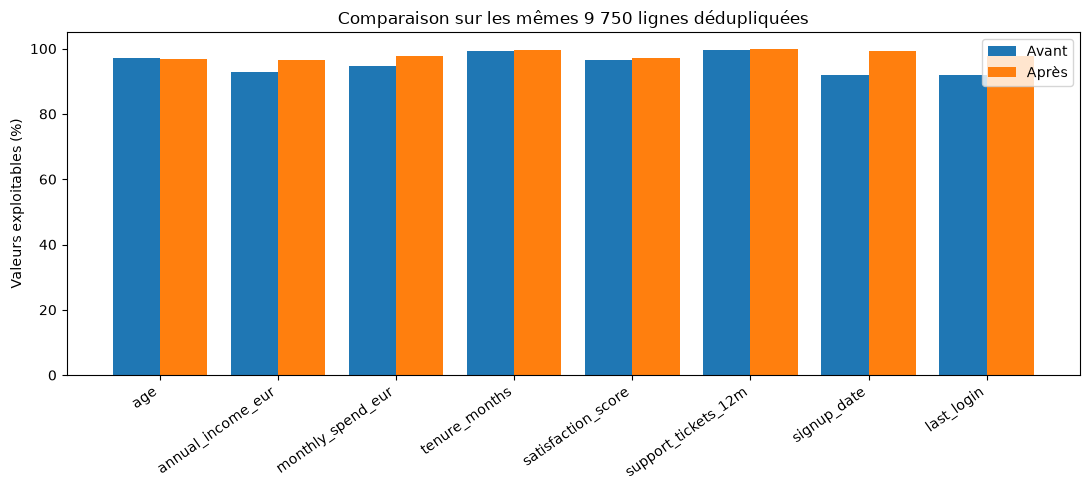

In [32]:
lignes_comparaison = []
for colonne in colonnes_numeriques:
    avant = pd.to_numeric(base[colonne], errors="coerce").notna().sum()
    apres = df[colonne].notna().sum()
    lignes_comparaison.append([colonne, int(avant), int(apres)])

for colonne, format_iso in [("signup_date", "%Y-%m-%d"),
                            ("last_login", "%Y-%m-%d %H:%M:%S")]:
    avant = pd.to_datetime(base[colonne], format=format_iso, errors="coerce").notna().sum()
    apres = df[colonne].notna().sum()
    lignes_comparaison.append([colonne, int(avant), int(apres)])

qualite = pd.DataFrame(lignes_comparaison, columns=["colonne", "valides_avant", "valides_apres"])
qualite["taux_avant_%"] = (qualite["valides_avant"] / len(base) * 100).round(2)
qualite["taux_apres_%"] = (qualite["valides_apres"] / len(df) * 100).round(2)
qualite["gain_points"] = (qualite["taux_apres_%"] - qualite["taux_avant_%"]).round(2)
print(qualite.to_string(index=False))

positions = np.arange(len(qualite))
plt.figure(figsize=(11, 5))
plt.bar(positions - 0.2, qualite["taux_avant_%"], width=0.4, label="Avant")
plt.bar(positions + 0.2, qualite["taux_apres_%"], width=0.4, label="Après")
plt.xticks(positions, qualite["colonne"], rotation=35, ha="right")
plt.ylabel("Valeurs exploitables (%)")
plt.title("Comparaison sur les mêmes 9 750 lignes dédupliquées")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.savefig(RACINE + "reports/figures/qualite_avant_apres.png", dpi=140)
plt.show()


## 8. Préparer le fichier final sans données directement identifiantes


In [ ]:
df_final = df.drop(columns=["customer_id", "full_name", "email"])

chemin_final = RACINE + "data/processed/customerpalace_clean.csv"
df_final.to_csv(chemin_final, index=False)

qualite.to_csv(RACINE + "reports/comparaison_qualite.csv", index=False)
print("Fichier nettoyé :", chemin_final)
print("Dimensions finales :", df_final.shape)
print("Valeurs manquantes restantes :")
print(df_final.isna().sum().sort_values(ascending=False).to_string())

Fichier nettoyé : ../data/processed/customerpalace_clean.csv
Dimensions finales : (9750, 16)
Valeurs manquantes restantes :
annual_income_eur      352
age                    297
satisfaction_score     287
monthly_spend_eur      232
last_login             216
city                   175
payment_method         117
signup_date             58
tenure_months           29
support_tickets_12m     13
plan                    10
country                  0
gender                   0
device                   0
marketing_opt_in         0
churned                  0


## 9. Analyse métier : trois constats sur le churn


In [ ]:
taux_global = df_final["churned"].mean() * 100
print(f"Churn global observé : {taux_global:.2f} %")

def tableau_churn(colonne):
    tableau = df_final.groupby(colonne, dropna=False)["churned"].agg(["count", "mean"])
    tableau = tableau.rename(columns={"count": "nombre_clients", "mean": "taux_churn"})
    tableau["taux_churn"] = (tableau["taux_churn"] * 100).round(2)
    return tableau.reset_index()

par_formule = tableau_churn("plan")
par_appareil = tableau_churn("device")
par_satisfaction = tableau_churn("satisfaction_score")

print("\n1. Selon la formule :")
print(par_formule.to_string(index=False))
print("\n2. Selon l'appareil :")
print(par_appareil.to_string(index=False))
print("\n3. Selon la satisfaction :")
print(par_satisfaction.to_string(index=False))

Churn global observé : 13.79 %

1. Selon la formule :
    plan  nombre_clients  taux_churn
   Basic            4020       16.52
    Gold              16        12.5
 Premium            1891       10.42
     Pro              33       15.15
Standard            3713       12.52
 Starter              54       16.67
     Vip              13        7.69
    <NA>              10        20.0

2. Selon l'appareil :
 device  nombre_clients  taux_churn
Desktop            2589       12.59
 Mobile            6272       14.33
 Tablet             889        13.5

3. Selon la satisfaction :
 satisfaction_score  nombre_clients  taux_churn
                  0              12        8.33
                  1               3       33.33
                  2              26       38.46
                  3             121       49.59
                  4             393       32.06
                  5             940       24.36
                  6            1745       18.68
                  7            216

## 10. Visualiser les trois analyses avec Matplotlib

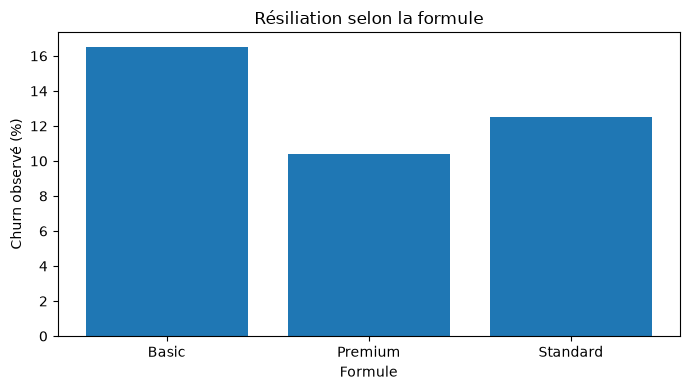

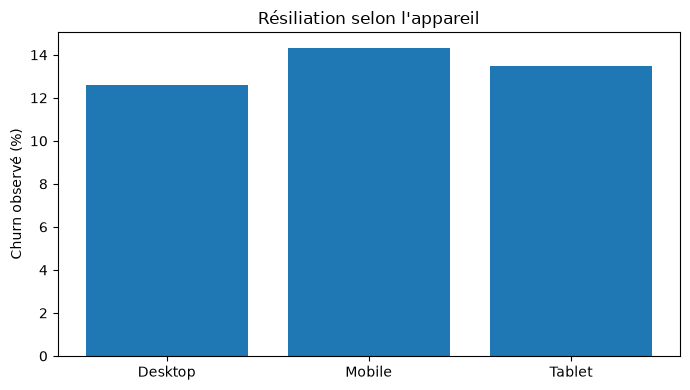

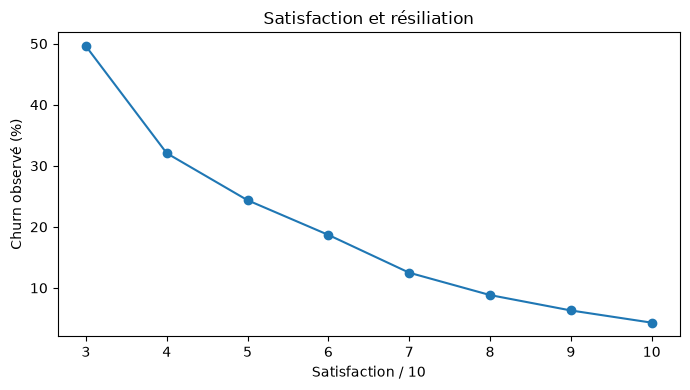

In [ ]:
formules_principales = par_formule[par_formule["nombre_clients"] >= 100]
plt.figure(figsize=(7, 4))
plt.bar(formules_principales["plan"], formules_principales["taux_churn"])
plt.title("Résiliation selon la formule")
plt.ylabel("Churn observé (%)")
plt.xlabel("Formule")
plt.tight_layout()
plt.savefig(RACINE + "reports/figures/churn_formule.png", dpi=140)
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(par_appareil["device"], par_appareil["taux_churn"])
plt.title("Résiliation selon l'appareil")
plt.ylabel("Churn observé (%)")
plt.tight_layout()
plt.savefig(RACINE + "reports/figures/churn_appareil.png", dpi=140)
plt.show()

satisfaction_ok = par_satisfaction[
    (par_satisfaction["nombre_clients"] >= 100) & par_satisfaction["satisfaction_score"].notna()
].sort_values("satisfaction_score")
plt.figure(figsize=(7, 4))
plt.plot(satisfaction_ok["satisfaction_score"], satisfaction_ok["taux_churn"], marker="o")
plt.title("Satisfaction et résiliation")
plt.xlabel("Satisfaction / 10")
plt.ylabel("Churn observé (%)")
plt.tight_layout()
plt.savefig(RACINE + "reports/figures/churn_satisfaction.png", dpi=140)
plt.show()


## Conclusion à expliquer à l'oral

- **Nous avons identifié les problèmes** : 10 000 lignes, 250 doublons stricts, formats incohérents.
- **Nous avons nettoyé sans inventer** : harmonisation explicite, conversions contrôlées, valeurs impossibles en `NaN`.
- **Nous avons prouvé les effets** : même population avant/après, graphiques et tableaux d'audit.
- **Nous avons produit trois analyses métier** : churn par formule, appareil et satisfaction.
- **Nous connaissons les limites** : une association n'est pas une causalité, les extrêmes ne sont pas vérifiés.

> **Bonus ML volontairement non inclus :** il était facultatif et aurait exigé d'autres bibliothèques que Pandas, NumPy et Matplotlib.